In [1]:
import rasterio
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Path to your .tif file
tif_path = '/work/uo1075/u241308/BB_challenge/Flood_data/Europe_RP50_filled_depth.tif'

# Open with rasterio
with rasterio.open(tif_path) as src:
    data = src.read()  # This gives a 3D numpy array: (bands, height, width)
    transform = src.transform
    crs = src.crs
    coords = {
        "y": np.arange(src.height) * transform[4] + transform[5],
        "x": np.arange(src.width) * transform[0] + transform[2],
        "band": np.arange(1, src.count + 1)
    }

    # Flip y-axis if needed (depends on coordinate direction)
    if transform[4] < 0:
        coords["y"] = coords["y"][::-1]
        data = data[:, ::-1, :]

    # Convert to xarray.DataArray
    da = xr.DataArray(
        data,
        dims=("band", "y", "x"),
        coords=coords,
        attrs={
            "crs": str(crs),
            "transform": transform.to_gdal()
        }
    )
    lon_min = -10
    lon_max = 0
    lat_min = 35
    lat_max = 45
    
    sel_lon = (da.x>=lon_min) & (da.x<=lon_max)
    sel_lat = (da.y>=lat_min) & (da.y<=lat_max)

    da = da[0,sel_lat,sel_lon]

In [17]:
da.shape

(1, 51992, 110162)

In [8]:
da = xr.where(da<-99,np.nan,da)

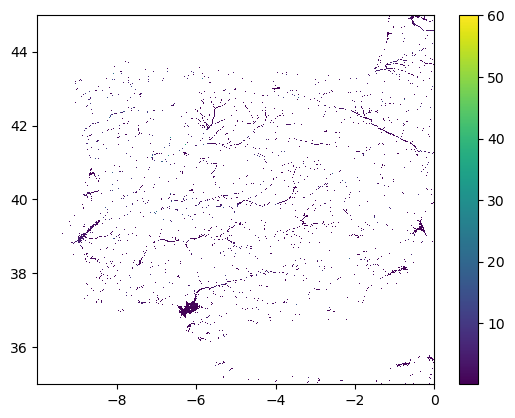

In [9]:
plt.pcolormesh(da.x,da.y,da)#,vmin=-10,vmax=20)
plt.colorbar()